In [ ]:
import os
import urllib.request
import pandas as pd

# Tự động tải dữ liệu nếu chưa có
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00502/online_retail_II.xlsx"
data_path = "../data/online_retail_II.xlsx"

if not os.path.exists(data_path):
    print("Đang cào dữ liệu từ UCI Machine Learning Repository (Khoảng 23MB)...")
    urllib.request.urlretrieve(url, data_path)
    print("Tải dữ liệu thành công và đã lưu vào thư mục data!")
else:
    print("Dữ liệu đã có sẵn trong thư mục data.")

# Đọc dữ liệu vào Pandas DataFrame
print("Đang đọc toàn bộ các sheet của file Excel (Quá trình này hơi lâu vì file hơn 1 triệu dòng)...")
# Đọc tất cả các sheet (sheet_name=None)
df_dict = pd.read_excel(data_path, sheet_name=None)

# Gộp tất cả các sheet lại thành một bảng duy nhất
df = pd.concat(df_dict.values(), ignore_index=True)

print(f"Hoàn tất! Tổng số dòng thực tế: {len(df)}")

# Hiển thị 5 dòng đầu tiên để xem mặt mũi dữ liệu
display(df.head())

Dữ liệu đã có sẵn trong thư mục data.
Đang đọc toàn bộ các sheet của file Excel (Quá trình này hơi lâu vì file hơn 1 triệu dòng)...


In [ ]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import xgboost as xgb
import joblib
import datetime as dt
import warnings
warnings.filterwarnings('ignore')

print("0. ĐỒNG BỘ CẤU TRÚC DỮ LIỆU...")
# Đổi tên các cột của bộ data mới cho khớp với cấu trúc hệ thống của bạn
df = df.rename(columns={
    'Customer ID': 'CustomerID',
    'Invoice': 'InvoiceNo',
    'Price': 'UnitPrice'
})

print("1. ĐANG LÀM SẠCH VÀ KẾT XUẤT DỮ LIỆU (DATA ENGINEERING)...")
# 1. Tính RFM
df_clean = df.dropna(subset=['CustomerID'])
df_clean = df_clean[df_clean['Quantity'] > 0]
df_clean['TotalPrice'] = df_clean['Quantity'] * df_clean['UnitPrice']
snapshot_date = df_clean['InvoiceDate'].max() + dt.timedelta(days=1)
rfm = df_clean.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'InvoiceNo': 'count',
    'TotalPrice': 'sum'
}).rename(columns={'InvoiceDate': 'Recency', 'InvoiceNo': 'Frequency', 'TotalPrice': 'Monetary'})

print("2. CHUẨN HÓA VÀ DÁN NHÃN K-MEANS...")
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm[['Recency', 'Frequency', 'Monetary']])
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
rfm['Customer_Segment'] = kmeans.fit_predict(rfm_scaled)

print("3. HUẤN LUYỆN LẠI XGBOOST VỚI DỮ LIỆU MỚI...")
X = rfm[['Recency', 'Frequency', 'Monetary']]
y = rfm['Customer_Segment']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

xgb_model = xgb.XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='mlogloss')
xgb_model.fit(X_train, y_train)

print("4. XUẤT FILE AI VÀ CÔNG CỤ CHUẨN HÓA...")
joblib.dump(xgb_model, '../models/best_ecommerce_model.joblib')
joblib.dump(scaler, '../models/scaler.joblib')
print("=> HOÀN TẤT! File AI đã được cập nhật thành công!")

0. ĐỒNG BỘ CẤU TRÚC DỮ LIỆU...
1. ĐANG LÀM SẠCH VÀ KẾT XUẤT DỮ LIỆU (DATA ENGINEERING)...
2. CHUẨN HÓA VÀ DÁN NHÃN K-MEANS...
3. HUẤN LUYỆN LẠI XGBOOST VỚI DỮ LIỆU MỚI...
4. XUẤT FILE AI VÀ CÔNG CỤ CHUẨN HÓA...
=> HOÀN TẤT! File AI đã được cập nhật thành công!


 Đã nạp thành công mô hình gốc: <class 'xgboost.sklearn.XGBClassifier'>

--- KẾT QUẢ DỰ BÁO TỪ FILE .JOBLIB ---
Khách hàng 1 được AI phân vào Nhóm: 1
Khách hàng 2 được AI phân vào Nhóm: 0
Khách hàng 3 được AI phân vào Nhóm: 1


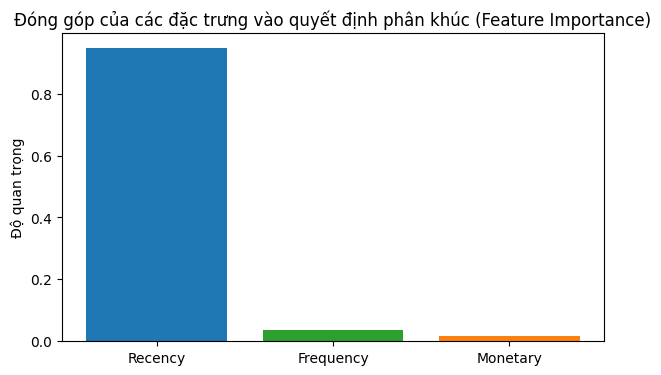

In [ ]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt

# 1. Gọi file nhị phân và CÔNG CỤ CHUẨN HÓA sống dậy
loaded_model = joblib.load('../models/best_ecommerce_model.joblib')
loaded_scaler = joblib.load('../models/scaler.joblib') # Bắt buộc nạp thêm Scaler
print("Đã nạp thành công bộ não AI và công cụ chuẩn hóa!")

# 2. Tạo ra 3 khách hàng giả định
test_customers = pd.DataFrame({
    'Recency': [5, 200, 45],
    'Frequency': [50, 1, 10],
    'Monetary': [1500, 15, 200]
})

# 3. ÉP KIỂU CHUẨN HÓA CHO KHÁCH HÀNG MỚI (BƯỚC QUAN TRỌNG)
test_customers_scaled = loaded_scaler.transform(test_customers)

# 4. Đưa qua mô hình để lấy dự báo
predictions = loaded_model.predict(test_customers_scaled)

print("\n--- KẾT QUẢ DỰ BÁO TỪ FILE .JOBLIB ---")
for i, pred in enumerate(predictions):
    print(f"Khách hàng {i+1} được AI phân vào Nhóm: {pred}")

# 5. Vẽ biểu đồ "khám nghiệm"
importance = loaded_model.feature_importances_
features = ['Recency', 'Frequency', 'Monetary']

plt.figure(figsize=(7, 4))
plt.bar(features, importance, color=['#1f77b4', '#2ca02c', '#ff7f0e'])
plt.title("Đóng góp của các đặc trưng vào quyết định phân khúc (Feature Importance)")
plt.ylabel("Độ quan trọng")
plt.show()

In [ ]:
print(f"Tổng số dòng ban đầu: {len(df)}")
print(f"Tổng số lượng khách hàng độc lập đưa vào huấn luyện: {len(rfm)}")

Tổng số dòng ban đầu: 525461
Tổng số lượng khách hàng độc lập đưa vào huấn luyện: 4314
